In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Capítulo 1

## Questão 13

In [3]:
def posicao_inicial():
    a = np.random.rand()

    if a < 0.25:
        p0 = np.array([[1],[0],[0]])
        return p0

    if a < 0.75:
        p0 = np.array([[0],[1],[0]])
        return p0

    else:
        p0 = np.array([[0],[0],[1]])
        return p0


def p_n(p_1):
    a = np.random.rand() 
    K = np.array([[0,1/5,1/8],[2/3,2/5,4/8],[1/3,2/5,3/8]])
    p_n1 = K@p_1

    if a < p_n1[0][0]:
        p_n = np.array([[1],[0],[0]]) 
        return p_n

    if a < (p_n1[0][0] + p_n1[1][0]):
        p_n = np.array([[0],[1],[0]]) 
        return p_n

    if a <= (p_n1[0][0] + p_n1[1][0] + p_n1[2][0]):
            p_n = np.array([[0],[0],[1]]) 
            return p_n


In [4]:
resultado = np.array([[0,0,0]])

for j in range(1_000_000):
    p0 = posicao_inicial()
    p1 = p_n(p0)

    for i in range(20):
        p1 = p_n(p1)


    p20 = p1
    resultado += p20.T
resultado = 1/1000000 * resultado
print(resultado)

[[0.143453 0.475808 0.380739]]


# Capítulo 2

## Questão 9

In [42]:
def n_caras_seguidos(n, p):
    e = (1-p**n)/((1-p)*p**n)
    return float(e)

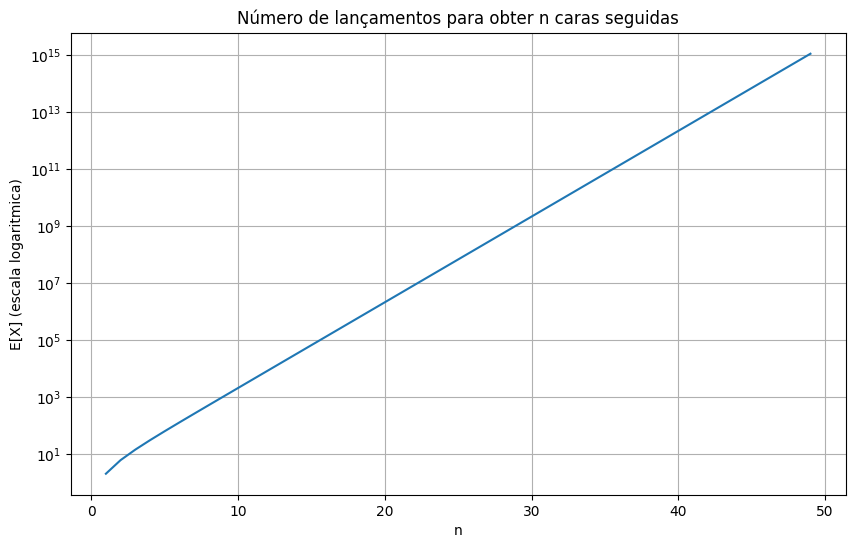

In [59]:
# Valores de n
n_values = np.arange(1, 50)

# Calcula os valores
e_x = np.array([n_caras_seguidos(n, 0.5) for n in n_values])



# ---------------------------
# Gráfico 2: Diferença
# ---------------------------

plt.figure(figsize=(10, 6))

plt.plot(n_values, e_x)
plt.yscale("log")
#plt.xscale("log")
plt.xlabel("n")
plt.ylabel("E[X] (escala logaritmica)")
plt.title("Número de lançamentos para obter n caras seguidas")
plt.grid()

plt.show()

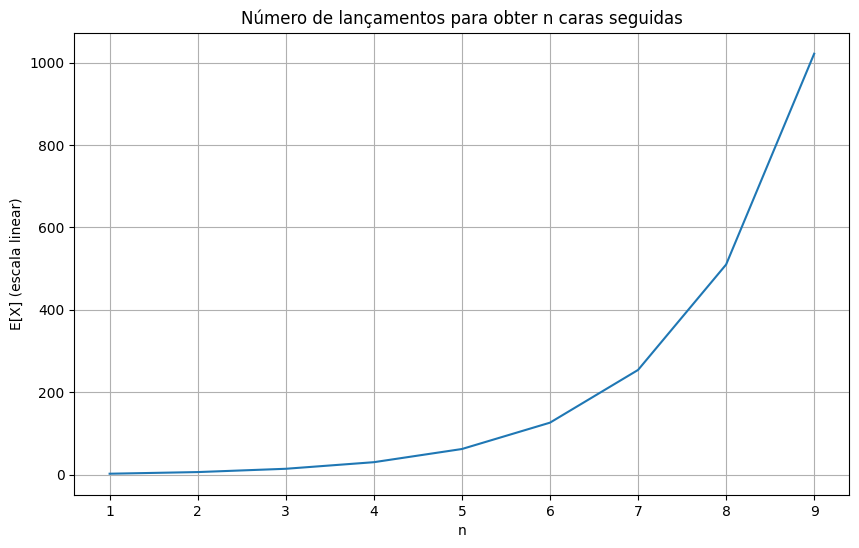

In [63]:
# Valores de n
n_values = np.arange(1, 10)

# Calcula os valores
e_x = np.array([n_caras_seguidos(n, 0.5) for n in n_values])



# ---------------------------
# Gráfico 2: Diferença
# ---------------------------

plt.figure(figsize=(10, 6))

plt.plot(n_values, e_x)
#plt.yscale("log")
#plt.xscale("log")
plt.xlabel("n")
plt.ylabel("E[X] (escala linear)")
plt.title("Número de lançamentos para obter n caras seguidas")
plt.grid()

plt.show()

# Capítulo 3

In [29]:
def soma_harmonica_exata(n):
    soma = 0
    for i in range(n):
        k = i+1
        soma += 1/k

    return soma

def soma_harmonica_aprox(n):
    gama = 0.577215664901532
    soma = np.log(n) + gama + 1/(2*n)
    return float(soma)
    

In [34]:
def E_exata(n):
    a = soma_harmonica_exata(2*n) -0.5*soma_harmonica_exata(n)
    return float(a)

def E_aprox(n):
    a = soma_harmonica_aprox(2*n) -0.5*soma_harmonica_aprox(n)
    return a

def erro_aprox(n):
    a = E_exata(n) - E_aprox(n)
    return a


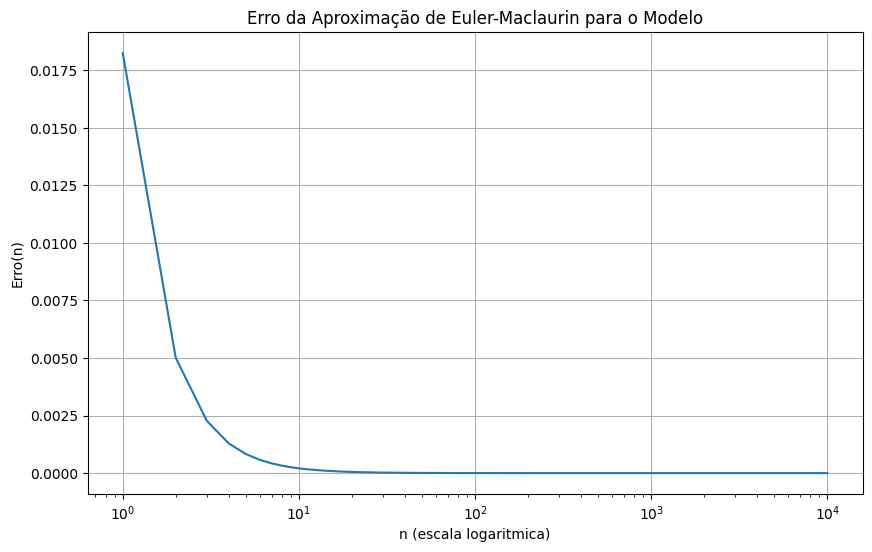

In [39]:
# Valores de n
n_values = np.arange(1, 10000)

# Calcula os valores
erro = np.array([erro_aprox(n) for n in n_values])



# ---------------------------
# Gráfico 2: Diferença
# ---------------------------

plt.figure(figsize=(10, 6))

plt.plot(n_values, erro)
plt.xscale("log")
plt.xlabel("n (escala logaritmica)")
plt.ylabel("Erro(n)")
plt.title("Erro da Aproximação de Euler-Maclaurin para o Modelo")
plt.grid()

plt.show()


# Capítulo X

## Questão Y

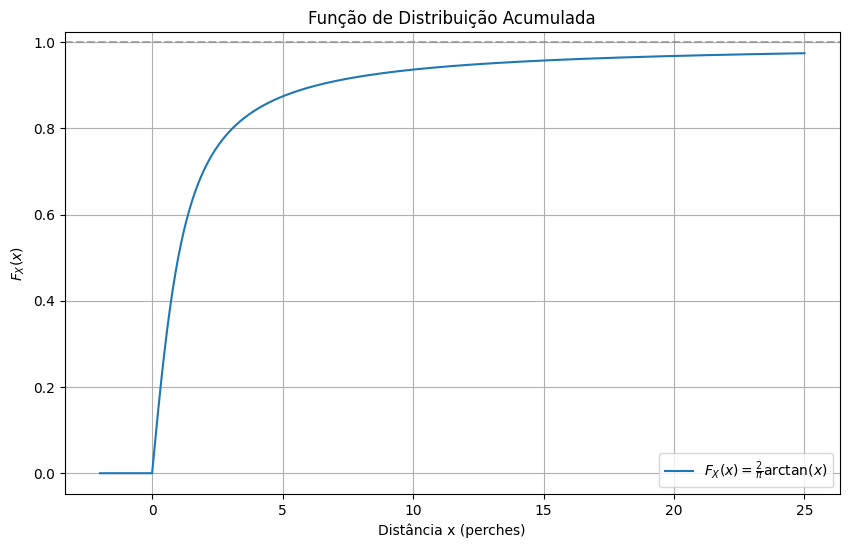

In [6]:
# Valores de x
x = np.linspace(-2, 25, 1000)

# Função de Distribuição Acumulada (FDA)
F_X = np.where(x < 0, 0, (2 / np.pi) * np.arctan(x))

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(x, F_X, label=r'$F_X(x) = \frac{2}{\pi}\arctan(x)$')

plt.xlabel('Distância x (perches)')
plt.ylabel(r'$F_X(x)$')
plt.title('Função de Distribuição Acumulada')
plt.axhline(y=1, color='gray', linestyle='--', alpha=0.6)
plt.grid(True)
plt.legend()

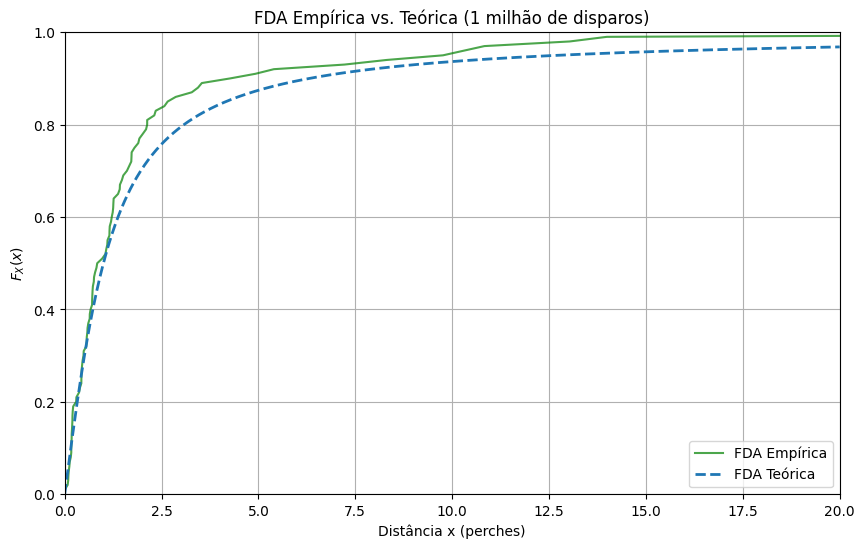

In [13]:
def simular_disparos(n=1_00, seed=42):
    rng = np.random.default_rng(seed)

    # Ângulos uniformemente distribuídos
    theta = rng.uniform(-np.pi/2, np.pi/2, n)

    # Distância horizontal (sempre positiva)
    distancias = np.abs(np.tan(theta))

    return distancias


# Simulação de 1 milhão de disparos
distancias = simular_disparos()

# FDA empírica
x_empirico = np.sort(distancias)
F_empirica = np.arange(1, len(x_empirico) + 1) / len(x_empirico)

# FDA teórica
x_teorico = np.linspace(0, 20, 1000)
F_teorica = (2 / np.pi) * np.arctan(x_teorico)

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(x_empirico, F_empirica,
         label='FDA Empírica',color='green', alpha=0.7)

plt.plot(x_teorico, F_teorica, '--',
         label='FDA Teórica', linewidth=2)

plt.xlim(0, 20)
plt.ylim(0, 1)

plt.xlabel('Distância x (perches)')
plt.ylabel(r'$F_X(x)$')
plt.title('FDA Empírica vs. Teórica (1 milhão de disparos)')

plt.grid(True)
plt.legend()
plt.show()

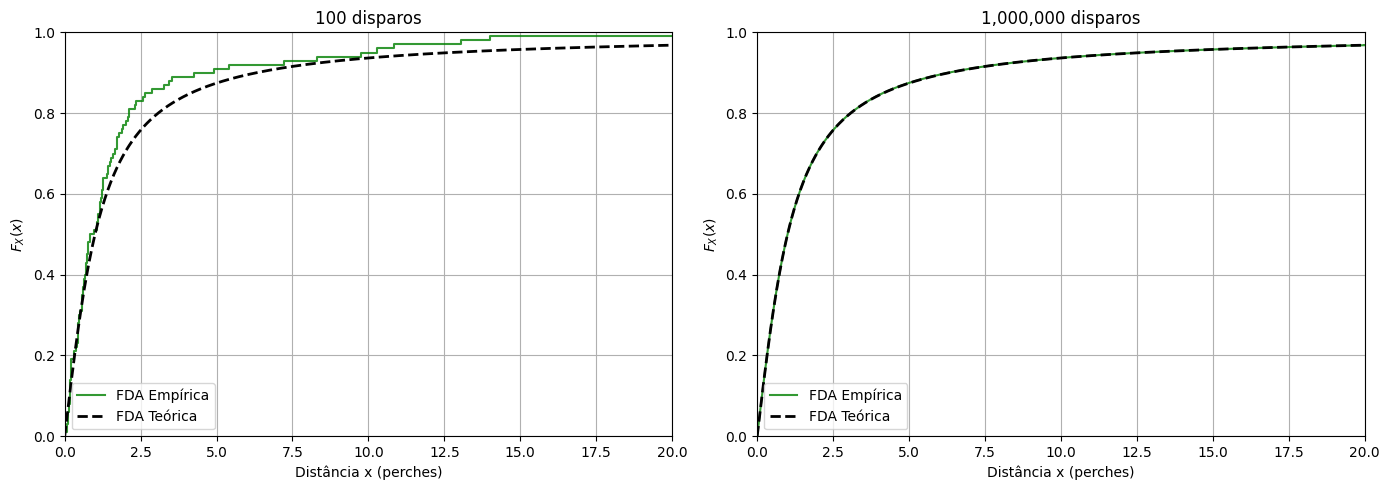

In [14]:
def simular_disparos(n, seed=42):
    rng = np.random.default_rng(seed)

    theta = rng.uniform(-np.pi/2, np.pi/2, n)
    distancias = np.abs(np.tan(theta))

    return np.sort(distancias)


# FDA teórica
x_teorico = np.linspace(0, 20, 1000)
F_teorica = (2 / np.pi) * np.arctan(x_teorico)

# Dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, n in zip(axes, [100, 1_000_000]):

    # Simulação
    x_empirico = simular_disparos(n)
    F_empirica = np.arange(1, n + 1) / n

    # FDA empírica
    ax.step(x_empirico, F_empirica,
            where='post', color='green',
            label='FDA Empírica', alpha=0.8)

    # FDA teórica
    ax.plot(x_teorico, F_teorica,
            '--', color='black',
            label='FDA Teórica', linewidth=2)

    ax.set_title(f'{n:,} disparos')
    ax.set_xlabel('Distância x (perches)')
    ax.set_ylabel(r'$F_X(x)$')

    ax.set_xlim(0, 20)
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()